# Predicción de la calidad del vino tinto con Naive Bayes

**Proyecto final** - Ingeniería del Conocimiento - Grupo 219900 - Ing. Rafael Hernández López

Este notebook integra el trabajo de todas las fases. Cada integrante escribe **solo su sección**, por turnos, en la rama `notebook-integrador`. Antes de escribir tu sección, ejecuta y lee las anteriores. El procedimiento está en `INSTRUCCIONES_GENERALES.md`, sección 6.

## Índice

1. [Fase 1: Origen y exploración de datos](#fase1)
2. [Fase 2: Preprocesamiento](#fase2)
3. [Fase 3A: Modelo Naive Bayes, entrenamiento](#fase3a)
4. [Fase 3B: Modelo Naive Bayes, evaluación y optimización](#fase3b)
5. [Fase 4: Dashboard de Business Intelligence](#fase4)
6. [Fase 5: Conclusiones](#fase5)

## Configuración

Define la raíz del proyecto para que las rutas relativas funcionen tanto si abres el notebook desde la raíz como desde `notebooks/`.

In [1]:
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: /home/emi/Naive-Bayes


<a id="fase1"></a>

# Fase 1: Origen y exploración de datos

**Responsable:** Mateo - **Turno:** 1

**Objetivo:** conocer el dataset antes de transformarlo: de dónde viene, qué mide cada columna, si está completo, si tiene registros repetidos y cómo se reparten las calificaciones de calidad.

- Script de la fase: `scripts/fase1_exploracion.py`
- Reporte completo: `docs/fase1_origen_datos.md`

**Fuente:** *Wine Quality* (vino tinto), UCI Machine Learning Repository. Cortez, P., Cerdeira, A., Almeida, F., Matos, T., y Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547-553.

### 1.1 Carga del dataset crudo

Se lee el CSV original de `data/raw/`. Este archivo nunca se modifica.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv(RAIZ / "data" / "raw" / "winequality-red.csv")
df_raw.head()

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### 1.2 Estructura: filas, columnas y tipos de datos

In [3]:
filas, columnas = df_raw.shape
print(f"Filas: {filas}  |  Columnas: {columnas}")
df_raw.dtypes

Filas: 1599  |  Columnas: 12


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

**Interpretación.** Hay 1,599 lotes y 12 columnas. Las 11 primeras son mediciones de laboratorio en decimales (`float64`) y son las **variables predictoras**. La última, `quality`, es un entero (`int64`) y es la **variable objetivo**: la calificación que dieron los catadores. Por eso la rúbrica habla de 12 atributos aunque el modelo use 11 para predecir.

### 1.3 Valores nulos y filas duplicadas

In [4]:
total_nulos = df_raw.isna().sum().sum()
duplicados = df_raw.duplicated().sum()

print(f"Valores nulos en total: {total_nulos}")
print(f"Filas duplicadas: {duplicados}")
print(f"Filas que quedan sin duplicados: {filas - duplicados}")

Valores nulos en total: 0
Filas duplicadas: 240
Filas que quedan sin duplicados: 1359


**Interpretación.** No hay valores nulos, así que no hay que rellenar nada. Pero hay **240 filas repetidas**. Si se dejan, al separar entrenamiento y prueba una copia puede quedar de cada lado y el modelo acertaría en la prueba porque ya vio ese lote, lo que infla el accuracy. Por eso la fase 2 elimina los duplicados y quedan 1,359 lotes.

### 1.4 Estadísticas descriptivas

In [5]:
resumen = df_raw.describe().T[["mean", "50%", "std", "min", "max"]]
resumen.columns = ["media", "mediana", "desv_std", "minimo", "maximo"]
resumen.round(3)

,media,mediana,desv_std,minimo,maximo
fixed acidity,8.320,7.900,1.741,4.600,15.900
volatile acidity,0.528,0.520,0.179,0.120,1.580
citric acid,0.271,0.260,0.195,0.000,1.000
residual sugar,2.539,2.200,1.410,0.900,15.500
chlorides,0.087,0.079,0.047,0.012,0.611
free sulfur dioxide,15.875,14.000,10.460,1.000,72.000
total sulfur dioxide,46.468,38.000,32.895,6.000,289.000
density,0.997,0.997,0.002,0.990,1.004
pH,3.311,3.310,0.154,2.740,4.010
sulphates,0.658,0.620,0.170,0.330,2.000


**Interpretación.** Las variables están en escalas muy distintas: `density` casi no cambia (desviación de 0.002) y `total sulfur dioxide` va de 6 a 289. Además, en variables como `residual sugar`, `chlorides` y `sulphates` el máximo está muy lejos de la mediana, lo que indica valores extremos. Los valores extremos los analiza la fase 2 y el escalado se hace en el pipeline de la fase 3.

### 1.5 Distribución de la variable objetivo `quality`

In [6]:
conteo = df_raw["quality"].value_counts().sort_index()
porcentaje = (df_raw["quality"].value_counts(normalize=True).sort_index() * 100).round(2)
tabla_quality = pd.DataFrame({"lotes": conteo, "porcentaje": porcentaje})

print(f"Calificaciones 5 y 6 juntas: {porcentaje.loc[[5, 6]].sum():.2f}% de los lotes")
tabla_quality

Calificaciones 5 y 6 juntas: 82.49% de los lotes


,lotes,porcentaje
quality,,
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


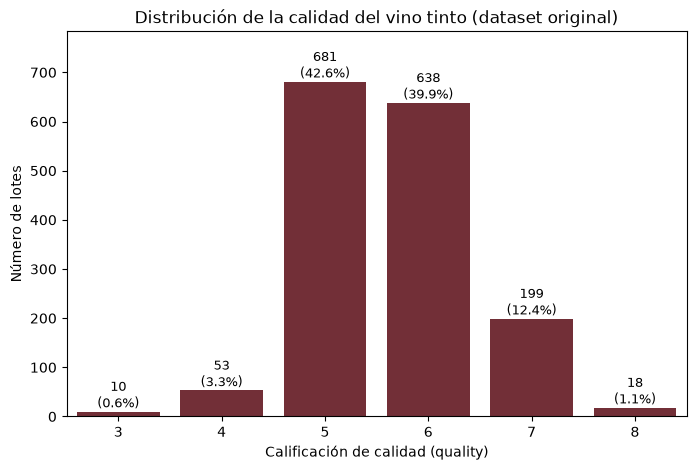

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=df_raw, x="quality", color="#722F37", saturation=1, ax=ax)
for barra in ax.patches:
    alto = int(barra.get_height())
    ax.annotate(f"{alto}\n({alto / filas:.1%})",
                (barra.get_x() + barra.get_width() / 2, alto),
                ha="center", va="bottom", fontsize=9)
ax.set_title("Distribución de la calidad del vino tinto (dataset original)")
ax.set_xlabel("Calificación de calidad (quality)")
ax.set_ylabel("Número de lotes")
ax.set_ylim(0, conteo.max() * 1.15)
plt.show()

**Interpretación.** Aunque la escala va de 0 a 10, solo aparecen calificaciones del 3 al 8, y el **82.49%** de los lotes tiene 5 o 6. De calidad 3 solo hay 10 lotes y de calidad 8 solo 18: con tan pocos ejemplos el modelo no puede aprender cómo son esos vinos y tendería a predecir siempre 5 o 6. Este **desbalance** es la razón por la que el equipo agrupa la calidad en `calidad_bin` (bueno si quality >= 6, malo si quality <= 5) y `calidad_3` (baja, media, alta).

**Conclusión de la fase 1.** El dataset está completo, pero tiene 240 duplicados que hay que quitar, clases muy desbalanceadas que obligan a agrupar la calidad y variables en escalas distintas. Como todas las variables se miden en el laboratorio antes de la cata, sirven para predecir la calidad **antes** de que el vino llegue al catador, que es lo que necesita la bodega.

<a id="fase2"></a>

# Fase 2: Preprocesamiento

**Responsable:** Pamela - **Turno:** 2

**Objetivo:** convertir el CSV crudo en un dataset limpio, consistente y listo para modelar, con un proceso reproducible: homogeneizar nombres y tipos, revisar nulos, eliminar duplicados, analizar valores atípicos y correlaciones, y crear las variables objetivo `calidad_bin` y `calidad_3`.

- Script de la fase: `scripts/fase2_preprocesamiento.py`
- Reporte completo: `docs/fase2_preprocesamiento.md`
- Salida: `data/processed/winequality-red-limpio.csv` (1,359 filas y 14 columnas, sin estandarizar)

En esta sección se ejecuto el mismo proceso del script paso a paso para explicar cada línea y cada decisión, y al final comparo el resultado con el CSV que generó el script. Partiendo de `df_raw`, el dataset crudo que cargó la fase 1.

### 2.1 Punto de partida

Se rabajó sobre una **copia** de `df_raw`. Así el dataset crudo queda intacto: la fase 1 lo sigue usando y nunca se modifica.

**Qué hace el código:**
- Las tres líneas `import` cargan las librerías: `pandas` (tablas y limpieza), `matplotlib` (figuras) y `seaborn` (gráficas estadísticas).
- `RAIZ` viene de la celda de Configuración; con ella se arma la ruta al CSV que generó el script, sin rutas de mi computadora.
- `df_raw.copy()` crea la copia sobre la que se hace toda la limpieza.

In [8]:
import pandas as pd                     
import matplotlib.pyplot as plt         
import seaborn as sns                  

RUTA_LIMPIO = RAIZ / "data" / "processed" / "winequality-red-limpio.csv"   

df = df_raw.copy()                      
print("Filas y columnas de partida:", df.shape)   # (1599, 12)

Filas y columnas de partida: (1599, 12)


### 2.2 Formato homogéneo: nombres y tipos de datos

Los nombres originales tienen espacios y mayúsculas (`fixed acidity`, `pH`). Se convirtieron al formato del contrato de datos del README.

**Qué hace el código:**
- `df.columns` guarda los nombres de las columnas. La *list comprehension* recorre cada nombre `c` y le aplica, en orden, `strip()` (quita espacios en los extremos), `lower()` (minúsculas: `pH` pasa a `ph`) y `replace(" ", "_")` (espacios a guion bajo: `fixed acidity` pasa a `fixed_acidity`).
- `astype(int)` deja `quality` como entero y `astype(float)` deja las otras 11 columnas como decimales.

In [9]:
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]   # renombra las 12 columnas

df["quality"] = df["quality"].astype(int)                        # quality: entero (calificación de 3 a 8)
columnas_decimales = [c for c in df.columns if c != "quality"]   # las otras 11 columnas (mediciones de laboratorio)
df[columnas_decimales] = df[columnas_decimales].astype(float)    # se aseguran como decimales

print(list(df.columns))   # nombres nuevos
df.dtypes                 # tipo de dato de cada columna

['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'quality']


fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
ph                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

**Interpretación.** Los nombres ya coinciden con el contrato de datos (`fixed_acidity`, `ph`, ...). Esto importa ya que en las siguientes fases se trabajan con esos mismos nombres, y porque los espacios y las mayúsculas dan problemas al escribir código y consultas. Los tipos ya eran correctos (11 `float64` y `quality` como `int64`), pero se declaran de forma explícita para que el proceso no dependa de cómo lea pandas el archivo.

### 2.3 Valores nulos y duplicados

Se revisó si hay datos faltantes y elimino las filas repetidas.

**Qué hace el código:**
- `df.isna()` marca `True` en cada celda vacía. El primer `sum()` cuenta por columna y el segundo suma todo.
- `drop_duplicates()` borra las filas idénticas a una anterior (se queda con la primera) y `reset_index(drop=True)` vuelve a numerar las filas desde 0.
- La resta `filas_antes - len(df)` dice cuántos duplicados se eliminaron.

In [10]:
nulos = int(df.isna().sum().sum())      
print("Valores nulos totales:", nulos)  
if nulos > 0:                           # si hubiera nulos...
    df = df.dropna()                    # ...se eliminan las filas incompletas

filas_antes = len(df)                   
df = df.drop_duplicates().reset_index(drop=True)   # borra duplicados y renumera desde 0
print("Duplicados eliminados:", filas_antes - len(df))  
print("Filas finales:", len(df))       

Valores nulos totales: 0
Duplicados eliminados: 240
Filas finales: 1359


**Interpretación.** No hay nulos, pero la revisión queda documentada en el código por si el archivo cambiara. Se eliminaron **240 duplicados** (15 % del archivo) y quedaron **1,359 lotes únicos**, la misma cifra que encontró la fase 1. Es importante quitarlos antes de modelar: si una copia cae en entrenamiento y otra en prueba, el modelo acierta esa fila porque ya la vio y no porque haya aprendido, y el accuracy sale inflado.

### 2.4 Valores atípicos

Un valor atípico es un dato muy alejado del resto. Para detectarlos uso la **regla 1.5 × IQR**: el IQR (rango intercuartílico) es la distancia entre Q1 (el valor que deja 25 % de los datos por debajo) y Q3 (el que deja 75 %), es decir, el ancho de la caja. Un dato es atípico si queda por debajo de `Q1 - 1.5 × IQR` o por encima de `Q3 + 1.5 × IQR`.

**Qué hace el código:**
- `quantile(0.25)` y `quantile(0.75)` calculan Q1 y Q3 de cada variable a la vez.
- Se comparan todos los datos con los dos límites (`|` significa "o") y `sum()` cuenta cuántos `True` hay por variable.
- Aquí **solo se detectan y se cuentan**: no se elimina ninguna fila.

In [11]:
variables = [c for c in df.columns if c != "quality"]   # las 11 variables fisicoquímicas (sin quality)

q1 = df[variables].quantile(0.25)    
q3 = df[variables].quantile(0.75)    
iqr = q3 - q1                        
limite_inf = q1 - 1.5 * iqr          # debajo de este límite, el dato es atípico
limite_sup = q3 + 1.5 * iqr          # encima de este límite, el dato es atípico

fuera = (df[variables] < limite_inf) | (df[variables] > limite_sup)      # True si el dato queda fuera
atipicos = fuera.sum().sort_values(ascending=False).rename("atipicos")   # cuenta por variable, de mayor a menor
atipicos

residual_sugar          126
chlorides                87
sulphates                55
total_sulfur_dioxide     45
fixed_acidity            41
density                  35
ph                       28
free_sulfur_dioxide      26
volatile_acidity         19
alcohol                  12
citric_acid               1
Name: atipicos, dtype: int64

**Cómo leer un diagrama de caja** (la gráfica de la siguiente celda):
- La **caja** va de Q1 a Q3 y contiene el 50 % central de los lotes.
- La **línea dentro de la caja** es la mediana.
- Los **bigotes** llegan hasta el dato más lejano que aún está dentro de 1.5 × IQR.
- Los **círculos sueltos** son los valores atípicos.
- **Cada cuadro tiene su propia escala vertical**, así que no se comparan alturas entre cuadros.

**Qué hace el código:** `plt.subplots(3, 4)` crea una cuadrícula de 12 cuadros; `zip(ejes.ravel(), variables)` empareja cada cuadro con una variable y `sns.boxplot` dibuja su caja. Como hay 11 variables, el cuadro 12 sobra y se oculta con `axis("off")`.

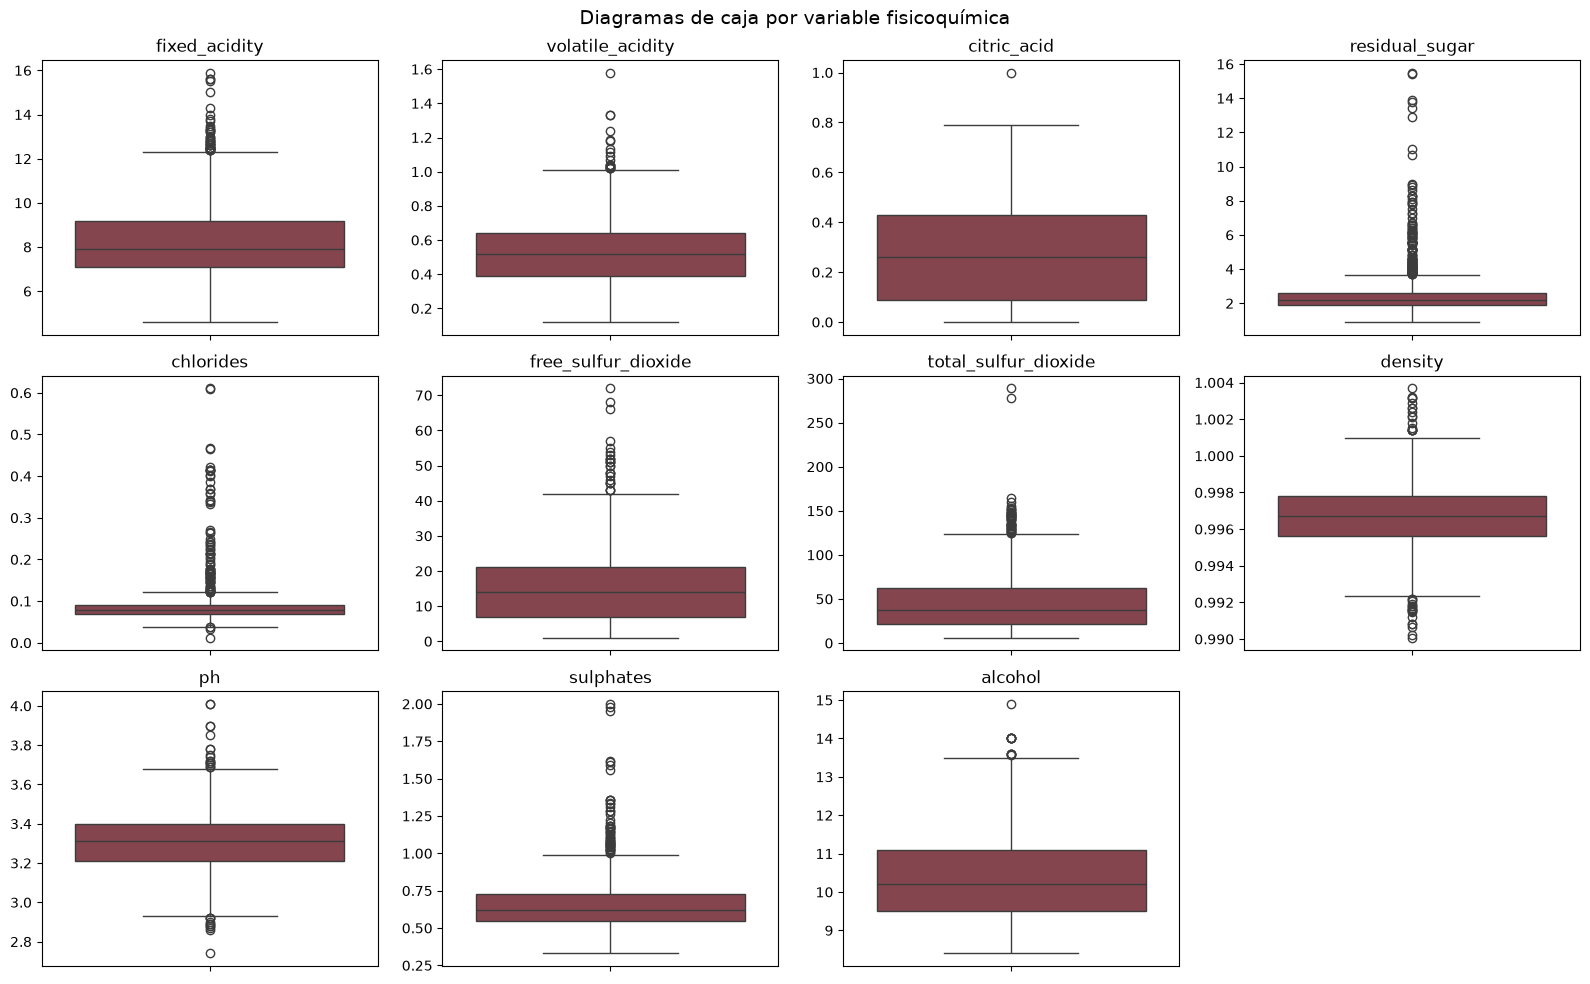

In [12]:
fig, ejes = plt.subplots(3, 4, figsize=(16, 10))   
for eje, var in zip(ejes.ravel(), variables):      
    sns.boxplot(y=df[var], ax=eje, color="#8e3b46") 
    eje.set_title(var)                            
    eje.set_ylabel("")                            
for eje in ejes.ravel()[len(variables):]:          
    eje.axis("off")                                
fig.suptitle("Diagramas de caja por variable fisicoquímica", fontsize=14)   
fig.tight_layout()                                 
plt.show()                                        

**Interpretación.** Hay atípicos en todas las variables. Los más numerosos están en `residual_sugar` (126), `chlorides` (87) y `sulphates` (55): su caja es muy angosta y tienen una fila larga de círculos hacia arriba, es decir, la mayoría de los lotes se parece y unos pocos tienen valores mucho más altos. `density` y `ph` se desvían hacia arriba y hacia abajo, y `total_sulfur_dioxide` llega a casi 290.

**Decisión: se conservan.** Los valores son químicamente posibles (por ejemplo, el pH va de 2.74 a 4.01 y el alcohol de 8.4 a 14.9), así que no parecen errores de captura. Además, un lote con acidez volátil o sulfatos extremos es justo el tipo de lote defectuoso que la bodega quiere detectar. Si los eliminara, le quitaría al modelo los casos que más le interesan al negocio.

### 2.5 Correlaciones

La **correlación de Pearson** mide qué tan relacionadas están dos variables, de -1 a +1: cerca de +0.5 es una relación positiva moderada (cuando una sube, la otra tiende a subir), cerca de 0 es que no hay relación lineal, y cerca de -0.4 es una relación negativa moderada (cuando una sube, la otra tiende a bajar).

**Qué hace el código:**
- `df[variables + ["quality"]].corr()` calcula la correlación entre todas las parejas de las 12 columnas y devuelve una tabla de 12 × 12.
- `sns.heatmap` la dibuja como mapa de calor: `annot=True` escribe el número en cada celda, `fmt=".2f"` usa dos decimales, `cmap="coolwarm"` pinta azul lo negativo y rojo lo positivo, `center=0` hace que el 0 sea casi blanco, `vmin=-1` y `vmax=1` fijan la escala y `square=True` hace las celdas cuadradas.
- La última línea toma la columna `quality`, quita su correlación consigo misma y la ordena de mayor a menor.

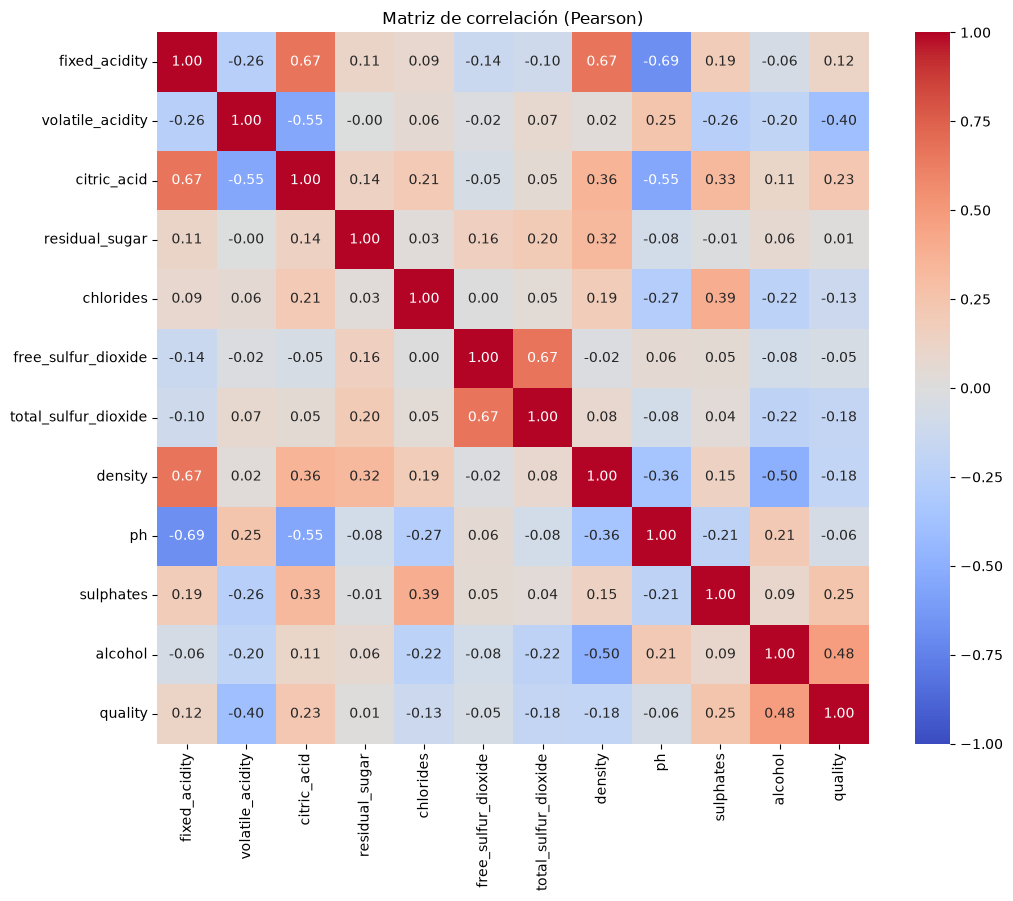

alcohol                 0.48
sulphates               0.25
citric_acid             0.23
fixed_acidity           0.12
residual_sugar          0.01
free_sulfur_dioxide    -0.05
ph                     -0.06
chlorides              -0.13
total_sulfur_dioxide   -0.18
density                -0.18
volatile_acidity       -0.40
Name: quality, dtype: float64

In [13]:
correlaciones = df[variables + ["quality"]].corr()   # matriz de correlación de Pearson (12 x 12)

fig, eje = plt.subplots(figsize=(11, 9))             
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, ax=eje)  
eje.set_title("Matriz de correlación (Pearson)")     
fig.tight_layout()                                   
plt.show()                                           

correlaciones["quality"].drop("quality").sort_values(ascending=False).round(2)   

**Cómo leer el mapa de calor.** Cada celda es la correlación entre la variable de su fila y la de su columna. El **rojo** es relación positiva, el **azul** negativa y el casi blanco cercana a 0; la barra de la derecha es la escala. La diagonal vale siempre 1.00 (cada variable con ella misma) y la matriz es simétrica, así que basta leer una mitad. La **última fila (`quality`)** es la que más importa para el modelo.

**Interpretación.** Con la calidad, las dos variables más relacionadas son el **alcohol (+0.48)**, porque los mejores vinos tienden a tener más alcohol, y la **acidez volátil (-0.40)**, porque más acidez volátil significa sabor a vinagre y peor calidad. Les siguen `sulphates` (+0.25) y `citric_acid` (+0.23); `residual_sugar` (+0.01) casi no se relaciona. Ninguna variable explica sola la calidad, lo que anticipa que el modelo tendrá límites.

Entre las variables también hay pares fuertes: `fixed_acidity` con `ph` (-0.69), con `density` (+0.67) y con `citric_acid` (+0.67), y `free_sulfur_dioxide` con `total_sulfur_dioxide` (+0.67). Esto va contra el supuesto de independencia entre las variables predictoras de Naive Bayes, Esto no impide utilizar Naive Bayes, pero es una característica del conjunto de datos que conviene mencionar, porque las relaciones entre predictores pueden afectar el comportamiento del modelo. Una correlación alta no prueba que una variable cause a la otra, y Pearson solo detecta relaciones lineales.

### 2.6 Variables objetivo: `calidad_bin` y `calidad_3`

La calidad (`quality`) toma valores de 3 a 8, pero hay muy pocos lotes en los extremos. Por eso se convierten en dos formas de clasificar (esto se llama **discretización**: pasar una variable numérica a categorías):

| Característica | `calidad_bin` | `calidad_3` |
|---|---|---|
| Número de categorías | 2 | 3 |
| Tipo de clasificación | Binaria | Multiclase |
| Categorías | `malo` (quality <= 5) y `bueno` (quality >= 6) | `baja` (<= 5), `media` (= 6) y `alta` (>= 7) |
| Objetivo | Simplificar la clasificación | Diferenciar niveles de calidad |

**Qué hace el código:**
- Para `calidad_bin`, `df["quality"] >= 6` da una serie de `True` y `False`, y `.map({True: "bueno", False: "malo"})` cambia cada valor por su texto.
- Para `calidad_3`, `pd.cut` recibe los límites de los intervalos (`bins=[0, 5, 6, 10]`) y su nombre (`labels`). Los intervalos **incluyen el límite derecho**: (0, 5] es `baja`, (5, 6] es `media` y (6, 10] es `alta`.
- `value_counts()` cuenta los lotes de cada clase. También se revisa que ningún lote se quede sin clase: `pd.cut` deja `NaN` si una calificación cae fuera de los intervalos (por ejemplo, un 0 o un valor mayor a 10).

In [14]:
df["calidad_bin"] = (df["quality"] >= 6).map({True: "bueno", False: "malo"})   # 2 clases

clase3 = pd.cut(
    df["quality"],                     
    bins=[0, 5, 6, 10],                 
    labels=["baja", "media", "alta"],   
)
print("Lotes sin clase (NaN) en calidad_3:", int(clase3.isna().sum()))   # 0: ninguna calificación queda fuera
df["calidad_3"] = clase3.astype(str)    

print(df["calidad_bin"].value_counts().to_string())   
print()
print(df["calidad_3"].value_counts().to_string())    

Lotes sin clase (NaN) en calidad_3: 0
calidad_bin
bueno    719
malo     640

calidad_3
baja     640
media    535
alta     184


**Interpretación.** Con el corte en 6, `calidad_bin` queda casi balanceada: 719 lotes `bueno` (53 %) y 640 `malo` (47 %), así que acertar no depende de predecir siempre la clase mayoritaria. En cambio, en `calidad_3` la clase `alta` tiene solo 184 lotes (13.5 %), por lo que está desbalanceada. No quedó ningún lote sin clase porque las calificaciones van de 3 a 8, dentro de los intervalos.

**Por qué importa para Naive Bayes.** Naive Bayes es un algoritmo de aprendizaje supervisado: clasifica un lote a partir de sus características. Las **variables predictoras (X)** son las 11 mediciones fisicoquímicas y la **variable objetivo (y)** es la categoría que se quiere predecir. Con estas dos columnas se pueden entrenar dos modelos y comparar su desempeño: uno **binario** (bueno o malo) y uno **multiclase** (baja, media o alta).

In [15]:
predictoras = variables                  # X: las 11 mediciones de laboratorio
objetivo_binario = "calidad_bin"         # y del modelo binario
objetivo_tres = "calidad_3"              # y del modelo de tres clases

print("Variables predictoras (X):", len(predictoras))
print("Objetivos posibles (y):", objetivo_binario, "o", objetivo_tres)
print("Columnas que NO entran en X:", ["quality", "calidad_bin", "calidad_3"])

Variables predictoras (X): 11
Objetivos posibles (y): calidad_bin o calidad_3
Columnas que NO entran en X: ['quality', 'calidad_bin', 'calidad_3']


**Interpretación.** `calidad_bin` y `calidad_3` se crean a partir de `quality`, así que son **dos formas alternativas de definir la variable objetivo**: se usa una o la otra como `y`, nunca como predictoras. Lo mismo vale para `quality`. Si alguna entrara en `X`, el modelo recibiría indirectamente la respuesta que debe aprender a predecir y sus métricas saldrían falsamente perfectas.

### 2.7 Resultado final y verificación

El script exporta el CSV con las 14 columnas del contrato de datos, en un orden fijo y **sin estandarizar** (los valores conservan sus unidades originales). Aquí no se vuelve a guardar el archivo, porque el CSV oficial es el que genera el script: se **lee y se compara** con lo que se obtiene en este notebook.

**Qué hace el código:**
- `COLUMNAS_CONTRATO` lista las 14 columnas en el orden acordado y `df[COLUMNAS_CONTRATO]` se queda solo con esas.
- `pd.read_csv(RUTA_LIMPIO)` lee el CSV que generó el script.
- `equals` y la comparación de listas verifican que el contenido y el orden de las columnas son idénticos.

In [16]:
COLUMNAS_CONTRATO = [                   
    "fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar",
    "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density",
    "ph", "sulphates", "alcohol", "quality", "calidad_bin", "calidad_3",
]
df_limpio = df[COLUMNAS_CONTRATO]       

df_script = pd.read_csv(RUTA_LIMPIO)     

print("Forma:", df_limpio.shape)       
print("Mismas columnas y orden que el CSV del script:", list(df_limpio.columns) == list(df_script.columns))
print("Mismo contenido que el CSV del script:", df_limpio.equals(df_script))
df_limpio.head()

Forma: (1359, 14)
Mismas columnas y orden que el CSV del script: True
Mismo contenido que el CSV del script: True


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,calidad_bin,calidad_3
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,malo,baja
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,malo,baja
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,malo,baja
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,bueno,media
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,malo,baja


**Interpretación.** El proceso hecho paso a paso en el notebook da exactamente el mismo resultado que el script: 1,359 lotes y 14 columnas, con los mismos nombres y el mismo orden. Eso muestra que la limpieza es **reproducible**: cualquiera puede ejecutar `python scripts/fase2_preprocesamiento.py` y obtener el mismo archivo.

**Conclusión de la fase 2.** Se partío de 1,599 lotes sin nulos, eliminó 240 duplicados y conservó los valores atípicos porque son lotes reales posibles. Las variables más relacionadas con la calidad son el alcohol (+0.48) y la acidez volátil (-0.40), y varias variables se relacionan entre sí, lo que limita a Naive Bayes. Creó `calidad_bin` (719 `bueno` y 640 `malo`) y `calidad_3` (640 `baja`, 535 `media` y 184 `alta`). El CSV limpio **no está estandarizado**: si estandarizara todo el dataset ahora, la media y la desviación estándar se calcularían también con filas que después serían de prueba (fuga de datos). El escalado se hace en el `Pipeline` de la fase 3, ajustado solo con los datos de entrenamiento.

<a id="fase3a"></a>

# Fase 3A: Modelo Naive Bayes, entrenamiento

**Responsable:** Braulio Herrera Peña - **Turno:** 3

**Objetivo:** implementar un pipeline reproducible de `GaussianNB` conectado al dataset limpio de la Fase 2, prevenir la fuga de datos (*data leakage*), comparar el desempeño entre clasificación de 3 clases y binaria, aplicar la configuración final de la Fase 3B y generar las predicciones honestas para Power BI.

- Script de la fase: `scripts/fase3_entrenamiento.py`
- Reporte completo: `docs/fase3_entrenamiento.md`
- Salida: `data/processed/predicciones.csv` (1,359 filas y 20 columnas)

### 3A.1 Fundamento teórico y diseño del Pipeline

- **Teorema de Bayes:** estima la probabilidad a posteriori $P(C_k \mid \mathbf{x}) = \frac{P(C_k)P(\mathbf{x}\mid C_k)}{P(\mathbf{x})}$ de que un lote sea `bueno` o `malo` a partir de sus propiedades fisicoquímicas.
- **Elección de `GaussianNB`:** las 11 variables predictoras son continuas reales; `GaussianNB` estima la media ($\mu_{jk}$) y varianza ($\sigma^2_{jk}$) por clase asumiendo normalidad condicional.
- **Prevención de fuga de datos (*data leakage*):** se encapsula `StandardScaler()` y `GaussianNB()` dentro de un `Pipeline` con división estratificada 80/20 (`random_state=42`), de modo que la estandarización se ajusta exclusivamente sobre `X_train`.

In [17]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RUTA_LIMPIO = RAIZ / "data" / "processed" / "winequality-red-limpio.csv"
RUTA_PREDICCIONES = RAIZ / "data" / "processed" / "predicciones.csv"

df_modelo = pd.read_csv(RUTA_LIMPIO)
print(f"Dataset limpio cargado: {df_modelo.shape[0]} filas x {df_modelo.shape[1]} columnas")

VARIABLES_11 = [
    "fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar",
    "chlorides", "free_sulfur_dioxide", "total_sulfur_dioxide", "density",
    "ph", "sulphates", "alcohol"
]

# Configuración final definida en Fase 3B
VARIABLES_SELECCIONADAS = ["alcohol", "volatile_acidity", "sulphates"]
VAR_SMOOTHING_FINAL = 1.0

def crear_pipeline(var_smoothing: float = 1e-9) -> Pipeline:
    return Pipeline([
        ("scaler", StandardScaler()),
        ("nb", GaussianNB(var_smoothing=var_smoothing)),
    ])

Dataset limpio cargado: 1359 filas x 14 columnas


### 3A.2 Experimentos de entrenamiento (80/20 estratificado)

Se ejecutan los tres experimentos sobre la misma partición (`1,087` lotes de entrenamiento y `272` de prueba, `random_state=42`) para comparar 3 clases vs. binario completo vs. binario final con las 3 variables seleccionadas y `var_smoothing=1.0`.

In [18]:
def ejecutar_experimento(X, y, nombre, var_smoothing=1e-9):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=42
    )
    pipe = crear_pipeline(var_smoothing=var_smoothing)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1_mac = f1_score(y_test, y_pred, average="macro")

    print(f"{'=' * 65}")
    print(f"EXPERIMENTO: {nombre}")
    print(f"Variables ({X.shape[1]}): {list(X.columns)} | var_smoothing: {var_smoothing}")
    print(f"Accuracy (prueba): {acc:.4f} | F1 Macro (prueba): {f1_mac:.4f}")
    print("-" * 65)
    print(classification_report(y_test, y_pred, digits=4))
    return pipe

pipe_exp1 = ejecutar_experimento(df_modelo[VARIABLES_11], df_modelo["calidad_3"], "1. Tres clases (baja/media/alta) - 11 variables")
pipe_exp2 = ejecutar_experimento(df_modelo[VARIABLES_11], df_modelo["calidad_bin"], "2. Binario (bueno/malo) - 11 variables")
pipe_exp3 = ejecutar_experimento(df_modelo[VARIABLES_SELECCIONADAS], df_modelo["calidad_bin"], "3. Binario final - 3 variables (Fase 3B)", VAR_SMOOTHING_FINAL)

EXPERIMENTO: 1. Tres clases (baja/media/alta) - 11 variables
Variables (11): ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates', 'alcohol'] | var_smoothing: 1e-09
Accuracy (prueba): 0.5809 | F1 Macro (prueba): 0.5596
-----------------------------------------------------------------
              precision    recall  f1-score   support

        alta     0.5000    0.4865    0.4932        37
        baja     0.6930    0.6172    0.6529       128
       media     0.5000    0.5701    0.5328       107

    accuracy                         0.5809       272
   macro avg     0.5643    0.5579    0.5596       272
weighted avg     0.5908    0.5809    0.5839       272

EXPERIMENTO: 2. Binario (bueno/malo) - 11 variables
Variables (11): ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'ph', 'sulphates'

### 3A.3 Predicciones honestas con validación cruzada (5-fold) para Power BI

Para entregar una predicción y probabilidad (`prob_bueno`) a los **1,359 lotes** sin evaluar sobre datos memorizados, se utiliza `cross_val_predict` con `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre el modelo final.

In [19]:
X_final = df_modelo[VARIABLES_SELECCIONADAS]
y_final = df_modelo["calidad_bin"]

pipe_cv = crear_pipeline(var_smoothing=VAR_SMOOTHING_FINAL)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

probas = cross_val_predict(pipe_cv, X_final, y_final, cv=cv, method="predict_proba")
pipe_cv.fit(X_final, y_final)

clases = list(pipe_cv.named_steps["nb"].classes_)
idx_bueno = clases.index("bueno")

df_pred = df_modelo.copy()
df_pred["id_lote"] = np.arange(1, len(df_pred) + 1)
df_pred["y_real"] = y_final.values
df_pred["y_pred"] = np.array([clases[i] for i in np.argmax(probas, axis=1)])
df_pred["prob_bueno"] = np.round(probas[:, idx_bueno], 6)
df_pred["acierto"] = (df_pred["y_real"] == df_pred["y_pred"]).astype(int)
df_pred["lote_en_riesgo"] = (df_pred["y_pred"] == "malo").astype(int)

print(f"Dimensiones predicciones: {df_pred.shape}")
print(f"Accuracy global en CV (1,359 lotes): {df_pred['acierto'].mean():.4f} ({df_pred['acierto'].sum()}/1359 aciertos)")
print(f"Lotes detectados en riesgo (malo): {df_pred['lote_en_riesgo'].sum()}")

# Validar coincidencia con el CSV generado por el script
df_pred_csv = pd.read_csv(RUTA_PREDICCIONES)
print("Coincide exactamente con data/processed/predicciones.csv:", df_pred.equals(df_pred_csv))
df_pred[["id_lote", "alcohol", "volatile_acidity", "sulphates", "y_real", "y_pred", "prob_bueno", "lote_en_riesgo"]].head()

Dimensiones predicciones: (1359, 20)
Accuracy global en CV (1,359 lotes): 0.7292 (991/1359 aciertos)
Lotes detectados en riesgo (malo): 676
Coincide exactamente con data/processed/predicciones.csv: True


,id_lote,alcohol,volatile_acidity,sulphates,y_real,y_pred,prob_bueno,lote_en_riesgo
0,1,9.4,0.70,0.56,malo,malo,0.324542,1
1,2,9.8,0.88,0.68,malo,malo,0.300050,1
2,3,9.8,0.76,0.65,malo,malo,0.357240,1
3,4,9.8,0.28,0.58,bueno,bueno,0.528673,0
4,5,9.4,0.66,0.56,malo,malo,0.343906,1


### 3A.4 Resumen e interpretación de resultados

| Experimento | Variable objetivo | Variables predictoras | `var_smoothing` | Accuracy (prueba) | F1 Macro (prueba) |
|---|---|---|---:|---:|---:|
| 1. Tres clases | `calidad_3` | 11 fisicoquímicas | `1e-9` | 0.5809 | 0.5596 |
| 2. Binario completo | `calidad_bin` | 11 fisicoquímicas | `1e-9` | 0.7353 | 0.7346 |
| 3. Binario final | `calidad_bin` | 3 (`alcohol`, `volatile_acidity`, `sulphates`) | `1.0` | **0.7500** | **0.7493** |

- **Interpretación.** Agrupar la calidad en formato binario (`bueno` vs. `malo`) eleva el accuracy de `0.5809` a `0.7353` al eliminar el solapamiento químico de la clase `media` y el desbalance de `alta`. Al conservar únicamente las 3 variables más informativas (`alcohol`, `volatile_acidity`, `sulphates`) y aplicar `var_smoothing=1.0`, el modelo reduce la colinealidad y alcanza **0.7500 de accuracy** y **0.7493 de F1 macro** en prueba.
- **Cierre de Fase 3A.** El archivo `data/processed/predicciones.csv` (1,359 filas × 20 columnas) entrega predicciones honestas fuera de muestra con un accuracy global en validación cruzada de **0.7292** (`991/1,359` aciertos) y **676 lotes detectados en riesgo**, listo para integrarse en el dashboard de Power BI.

<a id="fase3b"></a>

# Fase 3B: Modelo Naive Bayes, evaluación y optimización

**Responsable:** Octavio - **Turno:** 4

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.

<a id="fase4"></a>

# Fase 4: Dashboard de Business Intelligence

**Responsable:** Ximena - **Turno:** 5

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.

<a id="fase5"></a>

# Fase 5: Conclusiones

**Responsable:** Fátima - **Turno:** 6

> Pendiente. Escribe aquí tu sección: código, resultados y una celda de interpretación con tus palabras al final de cada resultado importante.